# Agreement networks

Roadmap step 2, part 1. Each Congress becomes a network:

- members are nodes;
- each pair is linked with a weight equal to their agreement on contested roll calls, meaning the share of votes they both cast as Yea or Nay where they voted the same way;
- pairs need at least 20 shared votes, otherwise there is no edge;
- the full weighted network is used, following [Waugh et al. (2009)](https://ar5iv.labs.arxiv.org/html/0907.3509) (confirmed source).

Then:

1. **Party modularity** measures how strongly the party split organises the network. Raw modularity is capped lower when one party holds most seats, so it is also shown **adjusted for seat shares** (modularity divided by its maximum, Newman's assortativity).
2. **Louvain** finds the best partition without being told party labels. It is run with 5 seeds at resolution 1, with other resolutions tested below.
3. **Cross-party share** is the share of Democrats and Republicans in a community mostly made up of the other party.
4. **Within-party structure** runs Louvain on each party alone, compared with 10 draws of a null where each roll call's votes are shuffled among members.

Scope matches notebook 01: Congresses with at least 10 Democrats and 10 Republicans from 1857, delegates excluded, a 2.5% near-unanimous cutoff by default, and the unfinished 119th Congress kept out of comparisons.

This describes voting behaviour on votes that reached the floor, not beliefs.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

sys.path.append(str(Path.cwd().parent))
sys.path.append(str(Path.cwd().parents[1] / "data_loading"))
from clustering import SOUTH, describe_communities, match_communities, network_summary
from voteview import build_matrix, load_members, load_rollcalls, load_votes

COLORS = {"D": "#2a78d6", "R": "#c93b3b"}
NEUTRAL = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})

INCOMPLETE_CONGRESS = 119
MIN_PARTY_MEMBERS = 10
CHAMBERS = ["House", "Senate"]
CUTOFFS = [0.0, 0.025, 0.10]


def first_year(congress):
    return 1789 + 2 * (congress - 1)


members = load_members()
rollcalls = load_rollcalls()
votes = load_votes()
voting_members = members[~members["is_delegate"]]
counts = voting_members.groupby(["congress", "chamber"])["party"].value_counts().unstack(fill_value=0)
selected = counts[(counts["D"] >= MIN_PARTY_MEMBERS) & (counts["R"] >= MIN_PARTY_MEMBERS)].index
print(f"{len(selected)} Congress and chamber combinations, from Congress {min(c for c, _ in selected)}")

info = members.drop_duplicates(["congress", "chamber", "icpsr"]).copy()
info["person"] = info["bioguide_id"].fillna("icpsr:" + info["icpsr"].astype(str))
info["south"] = info["state_abbrev"].isin(SOUTH)
info = info.set_index(["congress", "chamber", "icpsr"])

votes_by = votes.groupby(["congress", "chamber"])
rollcalls_by = rollcalls.groupby(["congress", "chamber"])
members_by = members.groupby(["congress", "chamber"])


def matrix_for(key, cutoff):
    return build_matrix(votes_by.get_group(key), rollcalls_by.get_group(key), members_by.get_group(key), min_minority_share=cutoff)


170 Congress and chamber combinations, from Congress 35


## Modularity and communities in each Congress

In [2]:
# Matrices are built here, so each worker receives only its own small matrix.
jobs = []
for key in selected:
    people = info.loc[key]
    for cutoff in CUTOFFS:
        full = cutoff == 0.025
        jobs.append(((key, cutoff, full), matrix_for(key, cutoff), people["party"], people["south"], full))
outputs = Parallel(n_jobs=8)(
    delayed(network_summary)(matrix, party, south, seeds=range(5) if full else range(1), factions=full)
    for _, matrix, party, south, full in jobs
)
runs = pd.DataFrame([
    {"congress": job[0][0][0], "chamber": job[0][0][1], "cutoff": job[0][1], **result}
    for job, (result, _) in zip(jobs, outputs)
])
runs["year"] = first_year(runs["congress"])
labels = {job[0][0]: community for job, (_, community) in zip(jobs, outputs) if job[0][2]}
networks = runs[runs["cutoff"] == 0.025].copy()
complete = networks[networks["congress"] < INCOMPLETE_CONGRESS]
print(len(runs), "runs")
print("Large communities (5%+ of members) in Louvain's best partition at resolution 1, by chamber:")
display(networks.groupby("chamber")["large_communities"].value_counts().unstack(fill_value=0))
print("Share of member pairs with fewer than 20 shared votes (no edge):", networks["missing_pairs"].describe().round(4).to_dict())
print("Seed stability (mean pairwise ARI across 5 Louvain seeds):")
display(networks.groupby("chamber")["seed_stability"].describe().round(3))
display(networks[networks["congress"].isin([60, 80, 90, 91, 95, 100, 105, 110, 115, 118])].set_index(["chamber", "congress"]).sort_index()[
    ["members", "party_modularity", "party_assortativity", "best_modularity", "large_communities", "party_ari", "cross_party_share"]].round(3))


510 runs
Large communities (5%+ of members) in Louvain's best partition at resolution 1, by chamber:


large_communities,2,3
chamber,,
House,81,4
Senate,78,7


Share of member pairs with fewer than 20 shared votes (no edge): {'count': 170.0, 'mean': 0.0114, 'std': 0.0201, 'min': 0.0, '25%': 0.0008, '50%': 0.0034, '75%': 0.0138, 'max': 0.151}
Seed stability (mean pairwise ARI across 5 Louvain seeds):


,count,mean,std,min,25%,50%,75%,max
chamber,,,,,,,,
House,85.0,0.998,0.014,0.875,1.0,1.0,1.0,1.0
Senate,85.0,0.978,0.062,0.684,1.0,1.0,1.0,1.0


members  party_modularity  party_assortativity  \
chamber congress                                                   
House   60            387             0.239                0.510   
        80            447             0.128                0.266   
        90            437             0.064                0.131   
        91            442             0.038                0.077   
        95            437             0.046                0.106   
        100           439             0.126                0.273   
        105           442             0.171                0.343   
        110           446             0.263                0.540   
        115           445             0.326                0.673   
        118           445             0.291                0.582   
Senate  60             92             0.125                0.325   
        80             97             0.127                0.256   
        90            101             0.033                0.073   
        91            102             0.044                0.091   
        95            104             0.038                0.081   
        100           101             0.089                0.183   
        105           100             0.172                0.349   
        110           102             0.180                0.354   
        115           104             0.228                0.447   
        118           104             0.274                0.515   

                  best_modularity  large_communities  party_ari  \
chamber congress                                                  
House   60                  0.241                  2      1.000   
        80                  0.130                  2      0.982   
        90                  0.097                  2      0.400   
        91                  0.071                  2      0.293   
        95                  0.074                  2      0.430   
        100                 0.130                  2      0.885   
        105                 0.174                  2      0.955   
        110                 0.263                  2      1.000   
        115                 0.326                  2      1.000   
        118                 0.291                  2      1.000   
Senate  60                  0.136                  2      0.778   
        80                  0.135                  2      0.802   
        90                  0.064                  2      0.112   
        91                  0.090                  2      0.196   
        95                  0.080                  2      0.183   
        100                 0.092                  2      0.846   
        105                 0.173                  2      0.921   
        110                 0.185                  2      0.960   
        115                 0.237                  2      1.000   
        118                 0.292                  2      0.960   

                  cross_party_share  
chamber congress                     
House   60                    0.000  
        80                    0.004  
        90                    0.183  
        91                    0.229  
        95                    0.172  
        100                   0.030  
        105                   0.011  
        110                   0.000  
        115                   0.000  
        118                   0.000  
Senate  60                    0.043  
        80                    0.052  
        90                    0.327  
        91                    0.275  
        95                    0.282  
        100                   0.040  
        105                   0.020  
        110                   0.010  
        115                   0.000  
        118                   0.010

**Louvain is stable across seeds.** Mean agreement between seeds is 0.998 in the House and 0.978 in the Senate, by adjusted Rand index. The lowest values, 0.875 and 0.684, fall in a few Congresses, so those partitions are less certain.

**At resolution 1**, the best partition has two large communities (each at least 5% of members) in 81 of 85 House Congresses and 78 of 85 Senate Congresses. The rest have three.

On a complete network with all-positive weights, Louvain will split even a smooth spread of members into two halves, so **two communities is partly what the method produces**. The informative question is whether those communities follow party, and the resolution test below checks for finer structure.

On average 1.1% of member pairs have fewer than 20 shared votes and so no edge, up to 15% in one Congress. Modularity treats a missing edge as zero agreement, which slightly understates agreement for members who served only part of a Congress.

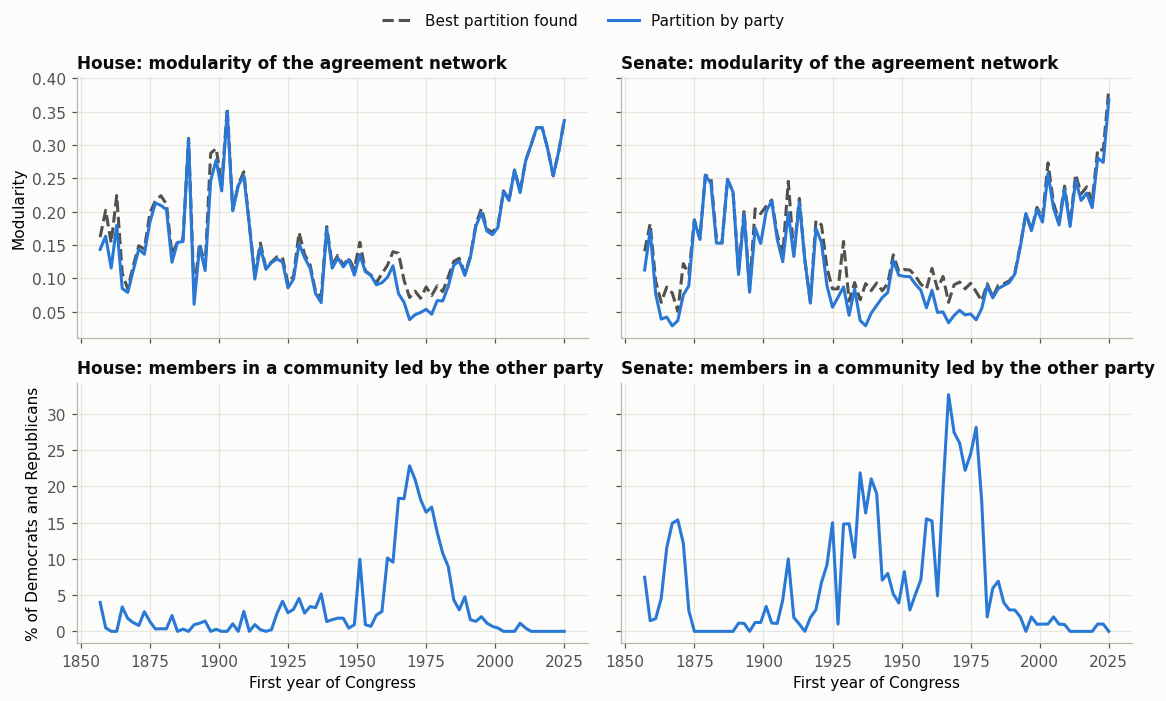

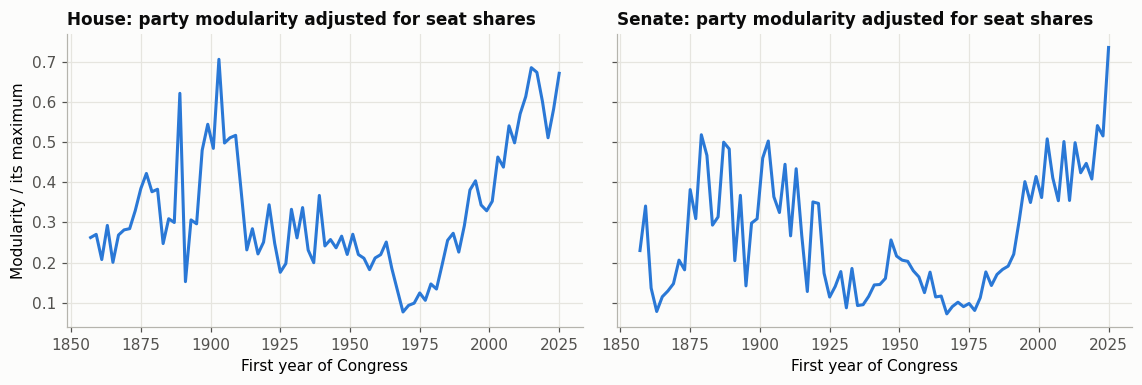

Closest point between the parties since 1900, complete Congresses


closest_year  value
chamber measure                                 
House   party_modularity             1969  0.038
        party_assortativity          1969  0.077
        cross_party_share            1969  0.229
        party_ari                    1969  0.293
Senate  party_modularity             1937  0.029
        party_assortativity          1967  0.073
        cross_party_share            1967  0.327
        party_ari                    1967  0.112

Senate seat split in 1937 and 1967 (Democratic share of two-party seats):


party,congress,D,R,dem_share
149,75,84,19,0.82
179,90,64,37,0.63


2015 to 2023 average against the pre-1945 extreme


,party_modularity,party_assortativity,cross_party_share,party_ari,max_party_modularity,max_party_assortativity,min_cross_party_share
chamber,,,,,,,
House,0.298,0.610,0.000,1.000,0.350,0.705,0.0
Senate,0.241,0.467,0.004,0.984,0.255,0.518,0.0


Last complete Congress with any member in a community led by the other party:
{'House': 2011, 'Senate': 2023}


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.4), sharex=True, sharey="row")
for column, chamber in enumerate(CHAMBERS):
    data = networks[networks["chamber"] == chamber]
    axes[0, column].plot(data["year"], data["best_modularity"], color=NEUTRAL, linestyle="--", label="Best partition found")
    axes[0, column].plot(data["year"], data["party_modularity"], color=COLORS["D"], label="Partition by party")
    axes[0, column].set_title(f"{chamber}: modularity of the agreement network")
    axes[1, column].plot(data["year"], data["cross_party_share"] * 100, color=COLORS["D"])
    axes[1, column].set_title(f"{chamber}: members in a community led by the other party")
    axes[1, column].set_xlabel("First year of Congress")
axes[0, 0].set_ylabel("Modularity")
axes[1, 0].set_ylabel("% of Democrats and Republicans")
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), sharey=True)
for axis, chamber in zip(axes, CHAMBERS):
    data = networks[networks["chamber"] == chamber]
    axis.plot(data["year"], data["party_assortativity"], color=COLORS["D"])
    axis.set_title(f"{chamber}: party modularity adjusted for seat shares")
    axis.set_xlabel("First year of Congress")
axes[0].set_ylabel("Modularity / its maximum")
fig.tight_layout()
plt.show()

rows = []
for chamber, frame in complete[complete["year"] >= 1900].groupby("chamber"):
    for measure, use_max in [("party_modularity", False), ("party_assortativity", False), ("cross_party_share", True), ("party_ari", False)]:
        row = frame.loc[frame[measure].idxmax() if use_max else frame[measure].idxmin()]
        rows.append({"chamber": chamber, "measure": measure, "closest_year": row["year"], "value": row[measure]})
print("Closest point between the parties since 1900, complete Congresses")
display(pd.DataFrame(rows).set_index(["chamber", "measure"]).round(3))

seats = counts.reset_index().assign(dem_share=lambda t: t["D"] / (t["D"] + t["R"]))
print("Senate seat split in 1937 and 1967 (Democratic share of two-party seats):")
display(seats[(seats["chamber"] == "Senate") & seats["congress"].isin([75, 90])][["congress", "D", "R", "dem_share"]].round(2))

recent = complete[complete["congress"].between(114, 118)].groupby("chamber")[["party_modularity", "party_assortativity", "cross_party_share", "party_ari"]].mean()
earlier = complete[complete["year"] < 1945].groupby("chamber").agg(
    max_party_modularity=("party_modularity", "max"), max_party_assortativity=("party_assortativity", "max"),
    min_cross_party_share=("cross_party_share", "min"))
print("2015 to 2023 average against the pre-1945 extreme")
display(recent.join(earlier).round(3))
print("Last complete Congress with any member in a community led by the other party:")
print(complete[complete["cross_party_share"] > 0].groupby("chamber")["year"].max().to_dict())


**What this shows**

- **Every measure puts peak convergence in 1969 in the House and 1967 in the Senate.** At those points 22.9% of House members and 32.7% of senators sat in a community led by the other party. Communities matched party only weakly (adjusted Rand index 0.29 and 0.11), and seat-adjusted party modularity was at its lowest (0.077 and 0.073).
- These agree with notebook 01's vote measures, using a different method.
- **The Senate's low raw modularity in 1937 comes from seat shares.** Democrats held 82% of two-party seats, which caps modularity. After adjustment, the Senate's lowest point is 1967, like the other measures.
- **Recent Congresses separate almost completely.** The last House member in the other party's community served in the Congress beginning in 2011. In 2023 the Senate figure is about one senator. From 2015 to 2023, communities matched party with an adjusted Rand index of 1.00 in the House and 0.98 in the Senate.
- **Recent separation is below its pre-1945 peak on these measures.** The 2015 to 2023 average of seat-adjusted party modularity is 0.610 in the House and 0.467 in the Senate, against pre-1945 maximums of 0.705 and 0.518. The sensitivity section checks this at every cutoff.

## Does modularity agree with DW-NOMINATE?

In [4]:
dw = voting_members[voting_members["party"].isin(["D", "R"])].groupby(["congress", "chamber", "party"])["nominate_dim1"].mean().unstack()
dw_gap = (dw["R"] - dw["D"]).rename("dw_gap").reset_index()
compared = complete.merge(dw_gap, on=["congress", "chamber"])
rows = []
for chamber, frame in compared.groupby("chamber"):
    frame = frame.sort_values("congress")
    changes = frame[["dw_gap", "party_modularity"]].diff().dropna()
    rows.append({
        "chamber": chamber,
        "levels_pearson": frame["dw_gap"].corr(frame["party_modularity"]),
        "levels_spearman": frame["dw_gap"].corr(frame["party_modularity"], method="spearman"),
        "changes_pearson": changes["dw_gap"].corr(changes["party_modularity"]),
    })
print("Party modularity against the DW-NOMINATE gap (delegates excluded), complete Congresses")
display(pd.DataFrame(rows).set_index("chamber").round(3))


Party modularity against the DW-NOMINATE gap (delegates excluded), complete Congresses


,levels_pearson,levels_spearman,changes_pearson
chamber,,,
House,0.793,0.761,0.247
Senate,0.702,0.675,0.143


Party modularity agrees with the DW-NOMINATE gap in levels: Pearson 0.79 in the House and 0.70 in the Senate. Agreement in changes between Congresses is weak, 0.25 and 0.14. These use the same roll calls, so this is consistency, not outside validation.

## Sensitivity to the near-unanimous cutoff

In [5]:
pivot = runs[runs["congress"] < INCOMPLETE_CONGRESS].pivot_table(
    index=["chamber", "congress"], columns="cutoff", values=["party_modularity", "party_assortativity", "cross_party_share"])
rows = []
for chamber in CHAMBERS:
    frame = pivot.loc[chamber]
    since_1900 = frame[first_year(frame.index) >= 1900]
    early = frame[first_year(frame.index) < 1945]
    recent_years = frame.loc[114:118]
    for cutoff in CUTOFFS:
        rows.append({
            "chamber": chamber, "cutoff": cutoff,
            "lowest_modularity_year": first_year(since_1900[("party_modularity", cutoff)].idxmin()),
            "lowest_assortativity_year": first_year(since_1900[("party_assortativity", cutoff)].idxmin()),
            "peak_cross_party_year": first_year(since_1900[("cross_party_share", cutoff)].idxmax()),
            "peak_cross_party_share": since_1900[("cross_party_share", cutoff)].max(),
            "modularity_corr_with_default": frame[("party_modularity", cutoff)].corr(frame[("party_modularity", 0.025)]),
            "modularity_2015_2023": recent_years[("party_modularity", cutoff)].mean(),
            "modularity_pre1945_max": early[("party_modularity", cutoff)].max(),
            "assortativity_2015_2023": recent_years[("party_assortativity", cutoff)].mean(),
            "assortativity_pre1945_max": early[("party_assortativity", cutoff)].max(),
        })
print("Sensitivity to the near-unanimous cutoff (cutoffs other than 2.5% use one Louvain seed; every comparison is within one cutoff)")
display(pd.DataFrame(rows).set_index(["chamber", "cutoff"]).round(3).T)


Sensitivity to the near-unanimous cutoff (cutoffs other than 2.5% use one Louvain seed; every comparison is within one cutoff)


chamber                          House                        Senate  \
cutoff                           0.000     0.025     0.100     0.000   
lowest_modularity_year        1969.000  1969.000  1969.000  1967.000   
lowest_assortativity_year     1969.000  1969.000  1969.000  1967.000   
peak_cross_party_year         1969.000  1969.000  1969.000  1967.000   
peak_cross_party_share           0.229     0.229     0.231     0.327   
modularity_corr_with_default     0.945     1.000     0.989     0.967   
modularity_2015_2023             0.229     0.298     0.347     0.208   
modularity_pre1945_max           0.321     0.350     0.364     0.252   
assortativity_2015_2023          0.467     0.610     0.710     0.403   
assortativity_pre1945_max        0.645     0.705     0.734     0.514   

chamber                                           
cutoff                           0.025     0.100  
lowest_modularity_year        1937.000  1937.000  
lowest_assortativity_year     1967.000  1967.000  
peak_cross_party_year         1967.000  1967.000  
peak_cross_party_share           0.327     0.327  
modularity_corr_with_default     1.000     0.992  
modularity_2015_2023             0.241     0.278  
modularity_pre1945_max           0.255     0.261  
assortativity_2015_2023          0.467     0.540  
assortativity_pre1945_max        0.518     0.527

**What this shows.** Every comparison here is within one cutoff.

- **The years hold at every cutoff.** Peak cross-party share and lowest seat-adjusted modularity are 1969 in the House and 1967 in the Senate. The Senate's 1937 low in raw modularity at 2.5% and 10% comes from seat shares, as explained above.
- **Recent separation stays below the pre-1945 peak at every cutoff in both chambers**, on both raw and seat-adjusted modularity. The closest case is the House at 10%: seat-adjusted modularity of 0.710 against 0.734.
- Levels depend on the cutoff, for example House seat-adjusted modularity for 2015 to 2023 runs from 0.467 to 0.710. Quote levels with their cutoff.
- Cutoffs other than 2.5% used one Louvain seed, which is acceptable given the stability above.

## Sensitivity to Louvain's resolution

In [6]:
KEY_CONGRESSES = [(80, "House"), (81, "House"), (85, "House"), (91, "House"), (118, "House"),
                  (75, "Senate"), (90, "Senate"), (118, "Senate")]
RESOLUTIONS = [1.0, 1.25, 1.5, 2.0]
jobs = [(key, resolution) for key in KEY_CONGRESSES for resolution in RESOLUTIONS]
outputs = Parallel(n_jobs=8)(
    delayed(network_summary)(matrix_for(key, 0.025), info.loc[key]["party"], info.loc[key]["south"],
                             seeds=range(3), factions=False, resolution=resolution)
    for key, resolution in jobs
)
rows = []
for (key, resolution), (result, community) in zip(jobs, outputs):
    people = info.loc[key]
    table = describe_communities(community, people["party"], people["south"])
    large_table = table[table["share_of_chamber"] >= 0.05]
    rows.append({
        "chamber": key[1], "year": first_year(key[0]), "resolution": resolution,
        "large_communities": result["large_communities"], "cross_party_share": result["cross_party_share"],
        "party_ari": result["party_ari"],
        "largest_southern_d_community": large_table.loc[large_table["share_d"] >= 0.8, "share_south"].max(),
    })
print("Louvain at higher resolutions, which favour more and smaller communities")
display(pd.DataFrame(rows).pivot_table(index=["chamber", "year"], columns="resolution",
                                       values=["large_communities", "cross_party_share", "largest_southern_d_community"]).round(2))


Louvain at higher resolutions, which favour more and smaller communities


cross_party_share                  large_communities            \
resolution                1.00  1.25  1.50 2.00              1.00 1.25 1.50   
chamber year                                                                  
House   1947              0.00  0.00  0.00  0.0               2.0  3.0  1.0   
        1949              0.01  0.00  0.00  0.0               3.0  3.0  2.0   
        1957              0.02  0.00  0.00  0.0               3.0  5.0  2.0   
        1969              0.23  0.08  0.02  0.0               2.0  2.0  2.0   
        2023              0.00  0.00  0.00  0.0               2.0  2.0  2.0   
Senate  1937              0.16  0.12  0.10  0.0               2.0  5.0  3.0   
        1967              0.33  0.04  0.00  0.0               2.0  4.0  1.0   
        2023              0.01  0.01  0.00  0.0               2.0  2.0  3.0   

                  largest_southern_d_community                    
resolution   2.00                         1.00  1.25  1.50  2.00  
chamber year                                                      
House   1947  1.0                         0.54  0.49  0.27  0.02  
        1949  0.0                         0.94  0.96  1.00   NaN  
        1957  0.0                         0.97  1.00  1.00   NaN  
        1969  0.0                         0.09  0.01  0.02   NaN  
        2023  1.0                         0.21  0.21  0.20   NaN  
Senate  1937  1.0                         0.35  0.93  1.00   NaN  
        1967  0.0                          NaN  1.00   NaN   NaN  
        2023  1.0                         0.07  0.07  0.09   NaN

**What this shows**

Higher resolution favours more, smaller communities.

- **Mid-century Congresses contain a Southern Democratic community** once the resolution allows a third group. In the Senate, communities that were 93% Southern (1937) and 100% Southern Democratic (1967) appear at resolution 1.25. In the House in 1949 and 1957, one appears even at resolution 1.
- **As a result, the cross-party share depends on resolution.** In the 1969 House it falls from 23% at resolution 1 to 8% at 1.25, because Southern Democrats form their own group rather than joining the Republican-led one. The cross-party share at resolution 1 measures how Louvain assigns that group when only two communities are allowed. It doesn't show that they belonged with Republicans.
- **In 2023, no Southern community appears at any resolution tested.** The House keeps two party communities through 1.5. The Senate splits into three at 1.5, but none is Southern and no member crosses party.
- At resolution 2.0 most Congresses break into many communities under 5% each, which isn't informative.
- Only eight key Congresses were tested. A full multi-resolution scan is a possible next step.

## Who formed the mixed communities?

In [7]:
tables = []
for key, community in labels.items():
    people = info.loc[key]
    table = describe_communities(community, people["party"], people["south"])
    table["congress"], table["chamber"] = key
    tables.append(table.reset_index())
communities = pd.concat(tables, ignore_index=True)
communities["year"] = first_year(communities["congress"])
large = communities[communities["share_of_chamber"] >= 0.05]

mixed = large[large["kind"] == "mixed"].groupby(["chamber", "congress"]).size().rename("mixed_blocs")
print("Complete Congresses with at least one large mixed community (5%+ of members, neither party 80%+):")
print(mixed.reset_index().query("congress < @INCOMPLETE_CONGRESS").groupby("chamber")["congress"].agg(["count", "min", "max"]).assign(
    first_year=lambda t: first_year(t["min"]), last_year=lambda t: first_year(t["max"])))

for key in [(80, "House"), (91, "House"), (118, "House"), (80, "Senate"), (90, "Senate"), (118, "Senate")]:
    print(f"\n{key[1]}, Congress beginning {first_year(key[0])}")
    display(large[(large["congress"] == key[0]) & (large["chamber"] == key[1])][
        ["community", "size", "share_of_chamber", "share_d", "share_r", "share_south", "kind"]].round(2))

crossers = []
for key, community in labels.items():
    people = info.loc[key].reindex(community.index)
    frame = pd.DataFrame({"community": community, "party": people["party"], "south": people["south"]})
    frame = frame[frame["party"].isin(["D", "R"])]
    majority = frame.groupby("community")["party"].agg(lambda s: s.value_counts().idxmax())
    frame["crosses"] = frame["party"] != frame["community"].map(majority)
    for party, part in frame.groupby("party"):
        crossers.append({
            "congress": key[0], "chamber": key[1], "party": party, "crossers": part["crosses"].sum(),
            "south_share_of_crossers": part.loc[part["crosses"], "south"].mean(),
            "south_share_of_party": part["south"].mean(),
        })
crossers = pd.DataFrame(crossers)
crossers["year"] = first_year(crossers["congress"])
print("\nWho sits in a community led by the other party, 1937 to 1979, complete Congresses")
era = crossers[crossers["year"].between(1937, 1979)]
display(era.groupby(["chamber", "party"]).apply(lambda g: pd.Series({
    "congresses_with_crossers": (g["crossers"] > 0).sum(),
    "mean_crossers": g["crossers"].mean(),
    "south_share_of_crossers": np.average(g["south_share_of_crossers"].fillna(0), weights=g["crossers"]) if g["crossers"].sum() else np.nan,
    "south_share_of_party": g["south_share_of_party"].mean(),
}), include_groups=False).round(3))

era = era.assign(southern=era["crossers"] * era["south_share_of_crossers"].fillna(0))
era = era.assign(other=era["crossers"] - era["southern"])
groups = era.groupby(["chamber", "party"])[["southern", "other"]].sum().unstack("party")
composition = pd.DataFrame({
    "southern_democrats": groups[("southern", "D")], "other_democrats": groups[("other", "D")],
    "southern_republicans": groups[("southern", "R")], "other_republicans": groups[("other", "R")],
})
print("Composition of all crossers, 1937 to 1979 (share of crossers, summed over Congresses)")
display(composition.div(composition.sum(axis=1), axis=0).round(3))


Complete Congresses with at least one large mixed community (5%+ of members, neither party 80%+):
         count  min  max  first_year  last_year
chamber                                        
House       12   36   96        1859       1979
Senate      29   35   96        1857       1979

House, Congress beginning 1947


,community,size,share_of_chamber,share_d,share_r,share_south,kind
189,0,249,0.56,0.00,1.00,0.01,R bloc
190,1,198,0.44,0.98,0.01,0.54,D bloc



House, Congress beginning 1969


,community,size,share_of_chamber,share_d,share_r,share_south,kind
237,0,237,0.54,0.30,0.70,0.37,mixed
238,1,205,0.46,0.86,0.14,0.09,D bloc



House, Congress beginning 2023


,community,size,share_of_chamber,share_d,share_r,share_south,kind
345,0,227,0.51,0.0,1.0,0.43,R bloc
346,1,218,0.49,1.0,0.0,0.21,D bloc


... (6 outputs left out)


Who sits in a community led by the other party, 1937 to 1979, complete Congresses


congresses_with_crossers  mean_crossers  \
chamber party                                            
House   D                          18.0         31.455   
        R                          20.0          7.545   
Senate  D                          21.0         10.182   
        R                          22.0          5.227   

               south_share_of_crossers  south_share_of_party  
chamber party                                                 
House   D                        0.824                 0.370  
        R                        0.000                 0.074  
Senate  D                        0.701                 0.351  
        R                        0.000                 0.046

Composition of all crossers, 1937 to 1979 (share of crossers, summed over Congresses)


,southern_democrats,other_democrats,southern_republicans,other_republicans
chamber,,,,
House,0.664,0.142,0.0,0.193
Senate,0.463,0.198,0.0,0.339


**What this shows**

- **Large mixed communities belong to the past.** A large community where neither party had 80% appeared in 12 House Congresses and 29 Senate Congresses, between 1857 and 1979. None appeared after 1979.
- **In the House, the crossers were mostly Southern Democrats.** From 1937 to 1979, 66% of all members in a community led by the other party were Southern Democrats, 19% non-Southern Republicans and 14% non-Southern Democrats.
- **In the Senate, crossing went both ways.** Southern Democrats were 46% of crossers, non-Southern Republicans sitting with Democrats 34%, and non-Southern Democrats 20%. In 1967, both Senate communities were mixed: one was 79% Democratic with a 21% non-Southern Republican minority.
- No Southern Republican crossed in either chamber.
- This is consistent with the conservative coalition of Southern Democrats and Republicans in the House. The Senate also had a liberal or moderate Republican group voting with Democrats. That interpretation is common in the literature but wasn't researched for this project, so treat it as unverified. Notebook 01's second-dimension hypothesis remains untested.

South here means the 11 former Confederate states, by the member's state. Adding border states such as Kentucky and Oklahoma isn't tested.

## Following communities across Congresses

In [8]:
MATCH = 0.5
lineages = {}
next_id = 0
records = []
for chamber in CHAMBERS:
    keys = sorted(k for k in labels if k[1] == chamber)
    previous = None
    for key in keys:
        people = info.loc[key]
        community = labels[key]
        by_person = pd.Series(community.values, index=people.reindex(community.index)["person"].values)
        by_person = by_person[~by_person.index.duplicated()]
        sizes = community.value_counts(normalize=True)
        assigned = {}
        if previous is not None and previous[0][0] == key[0] - 1:
            matches = match_communities(previous[1], by_person)
            for new in sizes.index:
                candidates = matches[matches["after"] == new].sort_values("jaccard", ascending=False)
                if len(candidates) and candidates.iloc[0]["jaccard"] >= MATCH:
                    assigned[new] = previous[2].get(candidates.iloc[0]["before"])
        for new in sizes.index:
            if assigned.get(new) is None:
                assigned[new] = next_id
                next_id += 1
            records.append({"chamber": chamber, "congress": key[0], "community": new, "lineage": assigned[new], "share": sizes[new]})
        previous = (key, by_person, assigned)
tracked = pd.DataFrame(records).merge(communities[["chamber", "congress", "community", "kind", "share_d", "share_south"]], on=["chamber", "congress", "community"])
tracked["year"] = first_year(tracked["congress"])
spans = tracked[tracked["share"] >= 0.05].groupby(["chamber", "lineage"]).agg(
    first_year=("year", "min"), last_year=("year", "max"), congresses=("congress", "nunique"),
    mean_share=("share", "mean"), mixed_congresses=("kind", lambda s: (s == "mixed").sum()),
    mean_share_d=("share_d", "mean"), mean_south=("share_south", "mean"))
print(f"Communities linked across Congresses when Jaccard overlap of returning people is at least {MATCH}")
main = spans.sort_values("congresses", ascending=False).groupby("chamber").head(2).index
print("Main lineages (the two longest-lived in each chamber):")
display(spans.loc[main].round(2))
print("Every other large lineage (5%+ of the chamber in at least one Congress), whatever its party mix:")
display(spans.drop(main).sort_values(["chamber", "first_year"]).round(2))
print("House communities in the Congresses beginning 1947, 1949 and 1951:")
display(large[(large["chamber"] == "House") & large["congress"].isin([80, 81, 82])][
    ["year", "community", "share_of_chamber", "share_d", "share_r", "share_south", "kind"]].round(2))


Communities linked across Congresses when Jaccard overlap of returning people is at least 0.5
Main lineages (the two longest-lived in each chamber):


first_year  last_year  congresses  mean_share  \
chamber lineage                                                  
House   1              1857       2025          85        0.49   
Senate  6              1857       2025          85        0.49   
        8              1873       2025          77        0.49   
House   0              1857       1949          47        0.49   

                 mixed_congresses  mean_share_d  mean_south  
chamber lineage                                              
House   1                       9          0.05        0.17  
Senate  6                      14          0.90        0.31  
        8                      14          0.08        0.16  
House   0                       3          0.94        0.43

Every other large lineage (5%+ of the chamber in at least one Congress), whatever its party mix:


first_year  last_year  congresses  mean_share  \
chamber lineage                                                  
House   2              1891       1891           1        0.26   
        4              1949       2025          39        0.50   
        5              1957       1959           2        0.16   
Senate  7              1857       1873           9        0.55   
        10             1927       1927           1        0.16   
        11             1933       1935           2        0.10   
        12             1943       1943           1        0.10   
        13             1963       1963           1        0.21   

                 mixed_congresses  mean_share_d  mean_south  
chamber lineage                                              
House   2                       0          1.00        0.06  
        4                       0          0.97        0.21  
        5                       0          0.99        0.95  
Senate  7                       1          0.02        0.12  
        10                      0          0.00        0.00  
        11                      2          0.24        0.11  
        12                      0          1.00        1.00  
        13                      0          1.00        0.95

House communities in the Congresses beginning 1947, 1949 and 1951:


,year,community,share_of_chamber,share_d,share_r,share_south,kind
189,1947,0,0.56,0.00,1.00,0.01,R bloc
190,1947,1,0.44,0.98,0.01,0.54,D bloc
193,1949,0,0.39,0.00,1.00,0.02,R bloc
194,1949,1,0.38,0.96,0.02,0.04,D bloc
195,1949,2,0.23,1.00,0.00,0.94,D bloc
198,1951,0,0.53,0.16,0.84,0.16,R bloc
199,1951,1,0.47,0.96,0.03,0.32,D bloc


**What this shows**

Communities are linked between consecutive Congresses when their returning members overlap by a Jaccard index of at least 0.5. People are matched by Bioguide ID.

- **Two main lineages run through nearly the whole period in each chamber.** In the House, the Democratic-led lineage is replaced in 1949.
- **Southern Democratic communities appear repeatedly but briefly at resolution 1**, at 10% to 23% of the chamber:
  - House 1949: 94% Southern, splitting the Democrats into a Northern and a Southern community;
  - House 1957 to 1959: 95% Southern;
  - Senate 1943 (100% Southern) and 1963 (95% Southern).
- None lasted more than two Congresses at resolution 1. The resolution test above suggests this is because Louvain merges them into a main community in other Congresses, not because the group disappeared.
- So the accurate statement is a **recurring, short-lived Southern Democratic community at resolution 1**, not "no third bloc".
- The 1949 split explains the House Democratic lineage break. 1949 is also the peak of House Democratic within-party structure in the next section.

## Structure inside each party

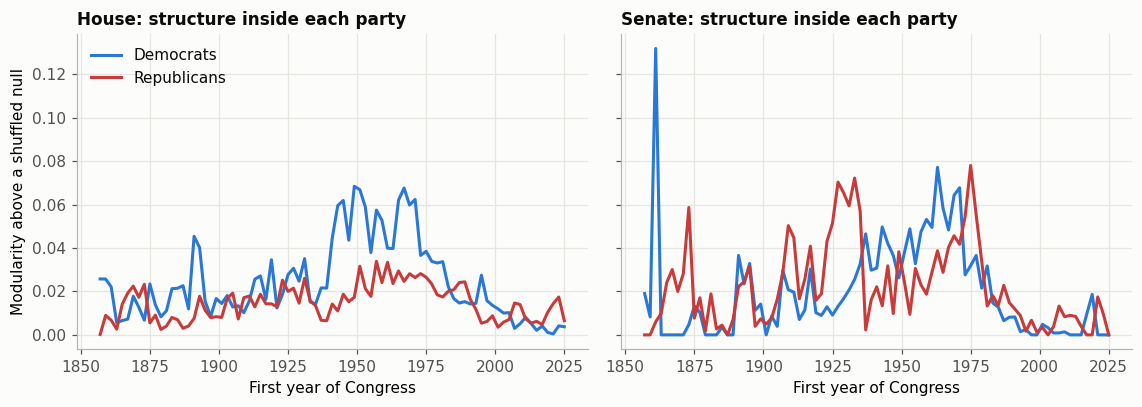

Mean null modularity over 10 shuffled-vote draws, range: {'min': -0.0, 'max': 0.0043}
Largest single null draw: 0.0051
Share of complete Congresses where observed structure beats every null draw:


,D,R
chamber,,
House,1.000,1.000
Senate,0.786,0.952


peak_year   peak  mean_1937_1979  mean_2015_2023  \
chamber party                                                     
House   D           1949  0.068           0.049           0.002   
        R           1957  0.034           0.022           0.011   
Senate  D           1861  0.132           0.044           0.006   
        R           1975  0.078           0.031           0.006   

               south_gap_1937_1979  south_gap_2015_2023  
chamber party                                            
House   D                    0.728                0.058  
        R                    0.108                0.268  
Senate  D                    0.603                0.196  
        R                    0.078                0.037

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for axis, chamber in zip(axes, CHAMBERS):
    data = networks[networks["chamber"] == chamber]
    for party, name in [("D", "Democrats"), ("R", "Republicans")]:
        axis.plot(data["year"], data[f"{party}_excess_modularity"], color=COLORS[party], label=name)
    axis.set_title(f"{chamber}: structure inside each party")
    axis.set_xlabel("First year of Congress")
axes[0].set_ylabel("Modularity above a shuffled null")
axes[0].legend(loc="upper left")
fig.tight_layout()
plt.show()

print("Mean null modularity over 10 shuffled-vote draws, range:", networks[["D_null_modularity", "R_null_modularity"]].stack().agg(["min", "max"]).round(4).to_dict())
print("Largest single null draw:", round(networks[["D_null_max", "R_null_max"]].max().max(), 4))
beats = pd.DataFrame({party: complete[f"{party}_modularity"] > complete[f"{party}_null_max"] for party in ["D", "R"]})
print("Share of complete Congresses where observed structure beats every null draw:")
display(beats.groupby(complete["chamber"]).mean().round(3))
summary = []
for chamber, frame in complete.groupby("chamber"):
    for party in ["D", "R"]:
        column = f"{party}_excess_modularity"
        peak = frame.loc[frame[column].idxmax()]
        summary.append({
            "chamber": chamber, "party": party, "peak_year": peak["year"], "peak": peak[column],
            "mean_1937_1979": frame.loc[frame["year"].between(1937, 1979), column].mean(),
            "mean_2015_2023": frame.loc[frame["congress"].between(114, 118), column].mean(),
            "south_gap_1937_1979": frame.loc[frame["year"].between(1937, 1979), f"{party}_south_gap"].mean(),
            "south_gap_2015_2023": frame.loc[frame["congress"].between(114, 118), f"{party}_south_gap"].mean(),
        })
display(pd.DataFrame(summary).set_index(["chamber", "party"]).round(3))


**What this shows**

The shuffled null removes all member consistency, so beating it shows structure inside a party. That could be distinct groups or a smooth spread that Louvain halves. It is therefore described as structure correlated with the South, not as proven factions.

- **Democratic structure tied to the South has largely disappeared.** From 1937 to 1979, House Democrats averaged 0.049 modularity above the null, and their two groups differed in Southern share by 73 points. In 2015 to 2023 those figures are 0.002 and 6 points. The Senate is similar: 0.044 to 0.006, and 60 to 20 points.
- **Republican structure has always been weaker.** In the House, its recent Southern gap (27 points) sits on very little structure (0.011), so it isn't evidence of a faction.
- **Null comparison:** null draws give mean modularity up to 0.004, and the largest single draw is 0.005. Observed structure beats every draw in all House Congresses, in 79% of Senate Congresses for Democrats, and in 95% for Republicans.
- The Senate Democratic spike in 1861 comes from a very small Civil War-era party and isn't meaningful.

## Summary

- **Convergence peaked in 1969 in the House and 1967 in the Senate.** Every network measure agrees on these years, including after adjusting for seat shares and at every cutoff, and so do notebook 01's vote measures.
- **At mid-century, Southern Democrats were a distinct group.** It appears as a separate community in some Congresses, and is merged into one of two main communities in others, depending on the Louvain resolution. In the House the crossers were mostly Southern Democrats. In the Senate, non-Southern Republicans voting with Democrats contributed almost as much.
- **Recent Congresses split cleanly by party** at every resolution tested. However, on seat-adjusted modularity, separation is still below its pre-1945 peak at every cutoff.
- **Democratic structure tied to the South has largely disappeared.**
- **Method notes:** two communities is partly what Louvain produces on these networks, so party alignment and resolution tests carry the evidence, not the count of communities.

Notebook 03 checks this with embeddings, and notebook 04 tests whether the change came from new members or sitting members.